# 06_01 — Lag study: PGLA jump vs charge

Does the PGLA jump correlate better with the charge (`BCM_GUN`) when it is **shifted in time** by up to ±5 shots?

- **PGLA jump** = `PGLA[631] − PGLA[636]`, the two fixed indices from the mean waveform (notebook 02)
- **Convention:** rows as recorded. For lag *L* we correlate `PGLA_drop[i + L]` with `BCM_GUN[i]`;
  a peak at **L = +1** means the PGLA value that belongs to shot *i* is stored one row later.
- **overall** r uses the raw values (includes the slow drift over the run);
  **shot-to-shot** r removes a 51-shot rolling mean first, which is what pins down the timing.
- Noise level for ~2100 shots: |r| ≲ 0.07.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
files = sorted(DATA_DIR.glob("chunk_*.h5"))

LAGS = np.arange(-5, 6)
I_HIGH, I_LOW = 631, 636
SERIES = ["#2a78d6", "#eb6834"]  # overall, shot-to-shot
MUTED = "#8a8985"


def load(key):
    return np.concatenate([h5py.File(path, "r")[key][:] for path in files])


pgla = load("PGLA/samples")[:, 0]
drop = pd.Series(pgla[:, I_HIGH] - pgla[:, I_LOW], name="PGLA_drop")
charge = pd.Series(load("BCM_GUN"), name="BCM_GUN")
print(f"{len(drop)} shots")

2100 shots


In [2]:
def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


r = pd.DataFrame({
    "overall": [charge.corr(drop.shift(-lag)) for lag in LAGS],
    "shot-to-shot": [detrend(charge).corr(detrend(drop).shift(-lag)) for lag in LAGS],
}, index=pd.Index(LAGS, name="lag"))
r.round(3).T

lag,-5,-4,-3,-2,-1,0,1,2,3,4,5
overall,0.172,0.159,0.156,0.185,0.149,0.18,0.237,0.165,0.147,0.167,0.153
shot-to-shot,0.012,-0.010,-0.013,0.036,-0.022,0.03,0.124,0.005,-0.023,0.011,-0.012


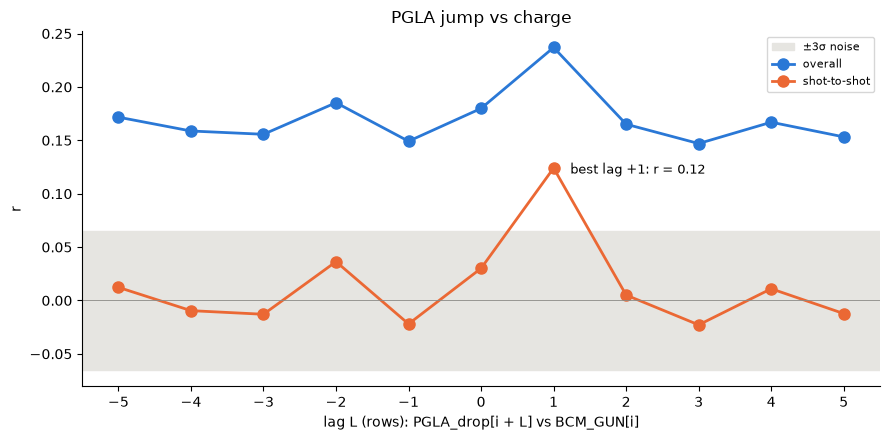

In [3]:
noise = 3 / np.sqrt(len(drop))
best = r["shot-to-shot"].abs().idxmax()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhspan(-noise, noise, color="#e6e5e1", label="±3σ noise")
for color, col in zip(SERIES, r.columns):
    ax.plot(LAGS, r[col], "o-", color=color, lw=2, ms=8, label=col)
ax.axhline(0, color=MUTED, lw=0.6)
ax.annotate(f"best lag {best:+d}: r = {r.loc[best, 'shot-to-shot']:.2f}", (best, r.loc[best, "shot-to-shot"]),
            xytext=(12, -4), textcoords="offset points", fontsize=9)
ax.set(xticks=LAGS, xlabel="lag L (rows): PGLA_drop[i + L] vs BCM_GUN[i]", ylabel="r", title="PGLA jump vs charge")
ax.legend(fontsize=8)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()

## Scatter: no shift vs best shift

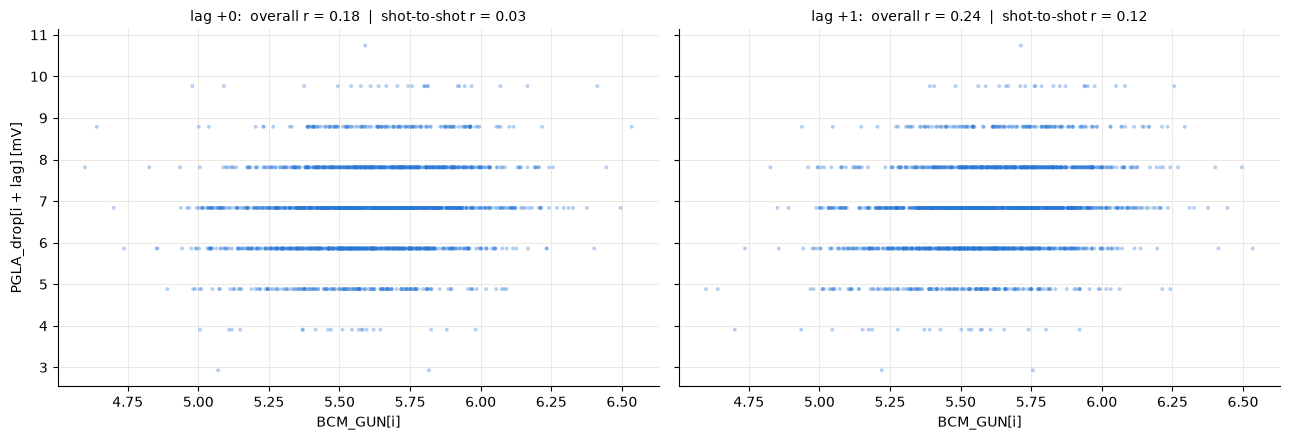

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, lag in zip(axes, [0, best]):
    shifted = drop.shift(-lag)
    ax.scatter(charge, shifted, s=8, color=SERIES[0], alpha=0.35, edgecolors="none")
    ax.set(xlabel="BCM_GUN[i]", title=f"lag {lag:+d}:  overall r = {r.loc[lag, 'overall']:.2f}  |  "
                                        f"shot-to-shot r = {r.loc[lag, 'shot-to-shot']:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel(f"PGLA_drop[i + lag] [mV]")
fig.tight_layout()